# Joint rigid shape and camera recovery

This active notebook reconstructs all **51 frames × 491 landmarks** from two-dimensional tracks. It reviews observations, physics/reference roles, fresh inverse results, measured-space residuals, metric-upgrade ablation and noise robustness. The source of the tracks is separately attributed to the providing author repository; acquisition origin is unverified. There is **no independent 3D truth**. The original closed-form rigid helper is a method baseline, not a measurement of actual geometry.

In [1]:
from pathlib import Path
import sys,time,json,subprocess
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.main import run
from src.solvers import reconstruct
from src.physics_model import forward,joint_alignment
from src.visualization import metrics,plot_shape
tracks=load_observations(ROOT/'data/raw_data.npz')
with np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as z:original={k:z[k].copy() for k in z.files}
print('Full tracks:',tracks.shape,'image pixels; independent GT absent')


Full tracks: (51, 491, 2) image pixels; independent GT absent


## 1. Observations

Every landmark has a supplied correspondence through all frames. The camera directions and scene depths are unknown. The plots show selected views for readability; **the inverse uses the complete array**. Coordinates remain in the supplied image-pixel convention.

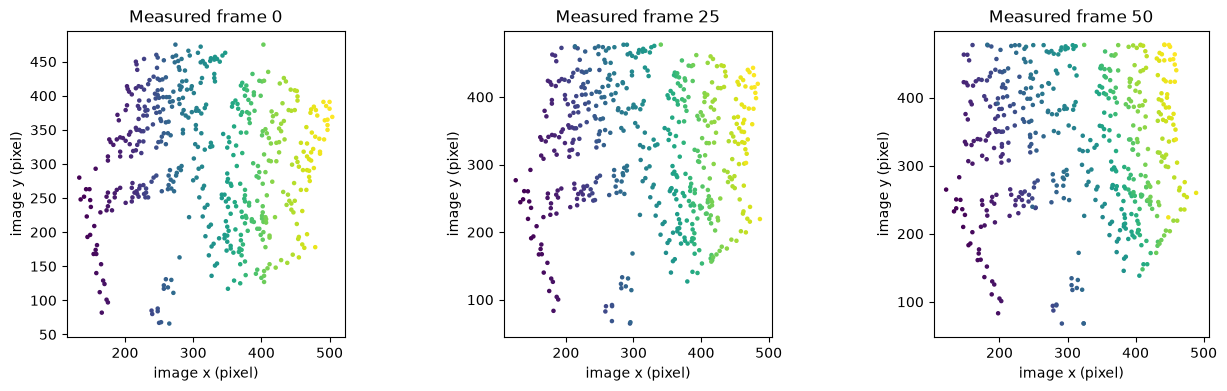

In [2]:
fig,ax=plt.subplots(1,3,figsize=(13,3.8),constrained_layout=True)
for a,f in zip(ax,[0,25,50]):
    a.scatter(tracks[f,:,0],tracks[f,:,1],c=np.arange(491),s=5,cmap='viridis');a.set(title=f'Measured frame {f}',xlabel='image x (pixel)',ylabel='image y (pixel)');a.set_aspect('equal')
plt.show()


## 2. Physics, ambiguity and reference roles

The model is $w(f,j)=R(f)X(j)+t(f)+e(f,j)$, with rigid shape $X$, camera $R$ and translation $t$. A centred track matrix has ideal rank three. An affine factorization alone leaves a general invertible ambiguity; camera inner-product constraints give a metric upgrade. The implemented helper includes its native joint correction described in the plans.

Shape has zero centroid and pixel-equivalent scale. A **single global orthogonal transformation, including reflection**, must act on both shape and camera rows. We do not fit a new translation/scale or rotate each camera independently. Original arrays are labelled method results, not GT.

## 3. Fresh complete reconstruction

This cell actively runs all local stages from the public tracks, writes all three required output keys and invokes the independent evaluator.

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 0.9999999999999997,
    "reconstruction_nrmse": 5.619064049854233e-16,
    "cameras_ncc": 1.0,
    "cameras_nrmse": 5.029464181870476e-16,
    "translations_ncc": 0.9999999999999999,
    "translations_nrmse": 9.207902794391104e-15,
    "projection_rmse": 2.3084638432541977
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "cameras_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "cameras_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "translations_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "translations_nrmse": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "projection_rmse": {
      "comparison": "<=",
      "boundary": 2.54
    }
  },
  "errors": []
}
Fresh CPU run

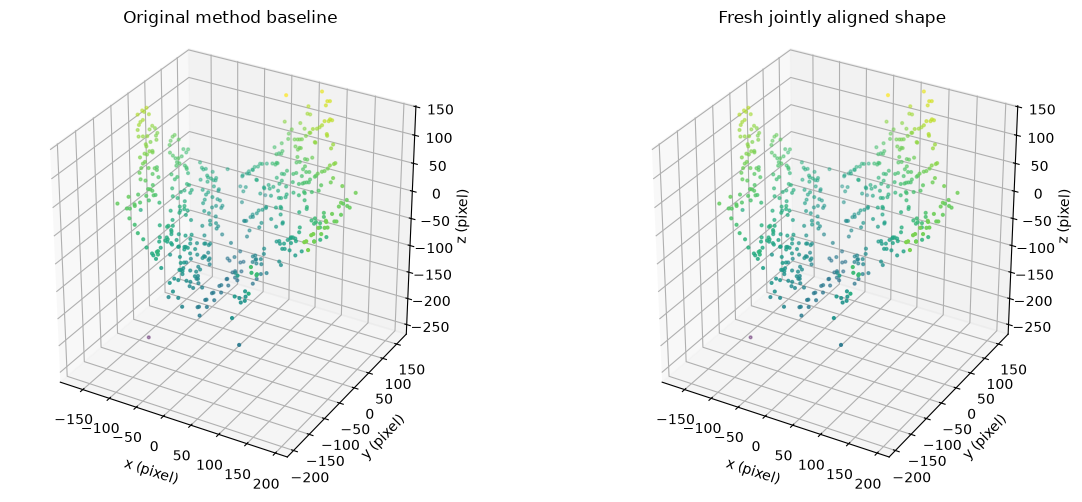

In [3]:
shape,cameras,translation,info,runtime=run(ROOT/'data/raw_data.npz',ROOT/'output/reconstruction.npz')
ref_shape=original['reconstruction'][0];ref_cameras=original['cameras'][0];ref_t=original['translations'][0]
aligned,aligned_camera,gauge=joint_alignment(shape,cameras,ref_shape)
result=subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(ROOT/'output/reconstruction.npz'),'--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
assert result.returncode==0,result.stderr
report=json.loads((ROOT/'output/judge_report.json').read_text());print(json.dumps(report,indent=2));print('Fresh CPU runtime (s):',runtime)
fig=plt.figure(figsize=(12,4.7),layout='constrained')
ax1=fig.add_subplot(121,projection='3d');ax2=fig.add_subplot(122,projection='3d')
plot_shape(ax1,ref_shape,'Original method baseline');plot_shape(ax2,aligned,'Fresh jointly aligned shape')
for axis in ['x','y','z']:
    bounds=(ref_shape[:,['x','y','z'].index(axis)].min(),ref_shape[:,['x','y','z'].index(axis)].max())
    getattr(ax1,'set_'+axis+'lim')(bounds);getattr(ax2,'set_'+axis+'lim')(bounds)
ax1.set_box_aspect(np.ptp(ref_shape,axis=0));ax2.set_box_aspect(np.ptp(ref_shape,axis=0))
plt.show()


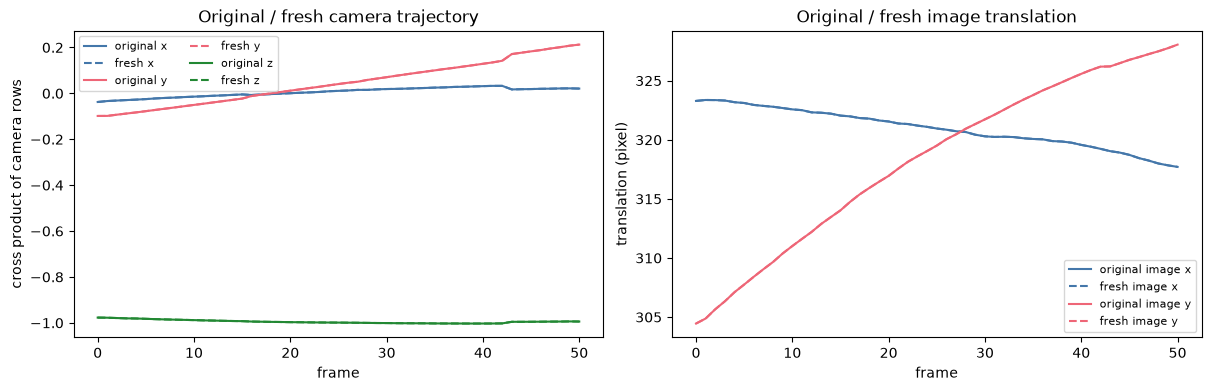

In [4]:
look_original=np.cross(ref_cameras[:,0],ref_cameras[:,1]);look_fresh=np.cross(aligned_camera[:,0],aligned_camera[:,1])
fig,ax=plt.subplots(1,2,figsize=(12,3.8),constrained_layout=True)
for k,(name,color) in enumerate(zip(['x','y','z'],['#4477aa','#ee6677','#228833'])):
    ax[0].plot(look_original[:,k],color=color,label='original '+name)
    ax[0].plot(look_fresh[:,k],color=color,linestyle='--',label='fresh '+name)
for k,(name,color) in enumerate(zip(['image x','image y'],['#4477aa','#ee6677'])):
    ax[1].plot(ref_t[:,k],color=color,label='original '+name)
    ax[1].plot(translation[:,k],color=color,linestyle='--',label='fresh '+name)
ax[0].set(xlabel='frame',ylabel='cross product of camera rows',title='Original / fresh camera trajectory');ax[0].legend(ncol=2,fontsize=8)
ax[1].set(xlabel='frame',ylabel='translation (pixel)',title='Original / fresh image translation');ax[1].legend(fontsize=8)
plt.show()


## 4. Joint comparisons and measured-space residuals

Reprojection uses submitted shape, cameras and translations together on every frame/landmark. Original/local agreement checks extraction; the nonzero measured residual and camera Gram errors expose the limitations of the rigid orthographic model on the supplied tracks.

Shape parity: {'ncc': 1.0000000000000002, 'nrmse': 5.754964611021643e-16} Camera parity: {'ncc': 1.0, 'nrmse': 4.732685779381832e-16}
Max shape/camera/translation parity errors: 1.6981971384666394e-12 3.4416913763379853e-15 7.389644451905042e-13
Complete image reprojection RMSE (pixel): 2.308463843254198
Absolute residual percentiles (pixel),50/99/100: [  0.32066049   6.54694458 106.9141589 ]


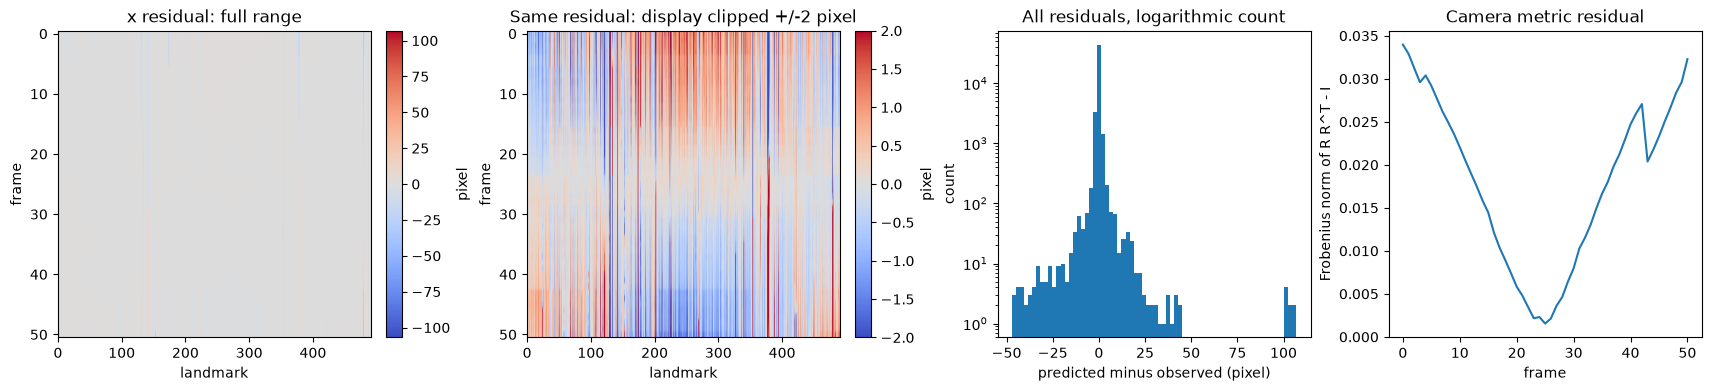

In [5]:
prediction=forward(shape,cameras,translation);residual=prediction-tracks
shape_metrics=metrics(aligned,ref_shape);camera_metrics=metrics(aligned_camera,ref_cameras)
print('Shape parity:',shape_metrics,'Camera parity:',camera_metrics)
print('Max shape/camera/translation parity errors:',np.max(np.abs(aligned-ref_shape)),np.max(np.abs(aligned_camera-ref_cameras)),np.max(np.abs(translation-ref_t)))
rmse=float(np.sqrt(np.mean(residual**2)));print('Complete image reprojection RMSE (pixel):',rmse)
print('Absolute residual percentiles (pixel),50/99/100:',np.percentile(np.abs(residual),[50,99,100]))
fig,ax=plt.subplots(1,4,figsize=(17,3.8),constrained_layout=True)
bound=np.abs(residual).max();im=ax[0].imshow(residual[:,:,0],aspect='auto',cmap='coolwarm',vmin=-bound,vmax=bound);fig.colorbar(im,ax=ax[0],label='pixel');ax[0].set(title='x residual: full range',xlabel='landmark',ylabel='frame')
im=ax[1].imshow(residual[:,:,0],aspect='auto',cmap='coolwarm',vmin=-2,vmax=2);fig.colorbar(im,ax=ax[1],label='pixel');ax[1].set(title='Same residual: display clipped +/-2 pixel',xlabel='landmark',ylabel='frame')
ax[2].hist(residual.ravel(),bins=70);ax[2].set_yscale('log');ax[2].set(title='All residuals, logarithmic count',xlabel='predicted minus observed (pixel)',ylabel='count')
gram=cameras@cameras.transpose(0,2,1);gram_error=np.linalg.norm(gram-np.eye(2),axis=(1,2));ax[3].plot(gram_error);ax[3].set(title='Camera metric residual',xlabel='frame',ylabel='Frobenius norm of R R^T - I')
plt.show()


## 5. Fresh affine-only ablation

Retain the rank-three affine factors before metric correction. They explain the same image observations but their camera rows do not have the orthographic metric. This diagnostic isolates why reprojection alone cannot establish Euclidean geometry. The affine factors are not relabelled as a physically calibrated competing reconstruction.

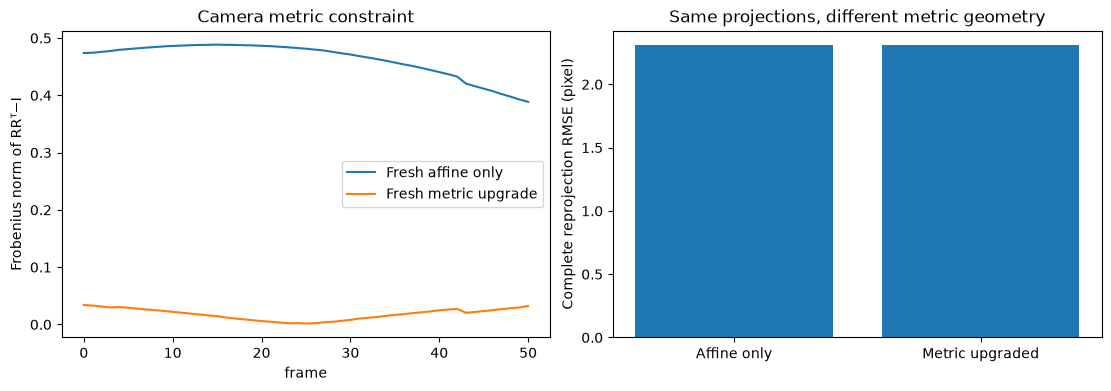

Mean camera Gram error: affine / metric 0.46304615099085966 0.017953834873394317


In [6]:
affine_camera=info['motion_affine'].reshape(51,2,3)
affine_shape=(info['shape_affine']*info['scale']).T
affine_projection=forward(affine_shape,affine_camera,translation)
affine_rmse=float(np.sqrt(np.mean((affine_projection-tracks)**2)))
affine_gram=affine_camera@affine_camera.transpose(0,2,1)
affine_error=np.linalg.norm(affine_gram-np.eye(2),axis=(1,2))
fig,ax=plt.subplots(1,2,figsize=(11,3.8),constrained_layout=True)
ax[0].plot(affine_error,label='Fresh affine only');ax[0].plot(gram_error,label='Fresh metric upgrade');ax[0].set(xlabel='frame',ylabel='Frobenius norm of RRᵀ−I',title='Camera metric constraint');ax[0].legend()
ax[1].bar(['Affine only','Metric upgraded'],[affine_rmse,rmse]);ax[1].set(ylabel='Complete reprojection RMSE (pixel)',title='Same projections, different metric geometry')
plt.show()
print('Mean camera Gram error: affine / metric',float(affine_error.mean()),float(gram_error.mean()))


## 6. Controlled robustness and conclusion

Add independent Gaussian image-coordinate perturbations of standard deviations 0.25 and 1 pixel to every track component, and reconstruct both full arrays anew. These declared artificial perturbations assess sensitivity; they are not an estimate of actual instrument noise. Compare to the fresh unperturbed result using the same joint gauge.

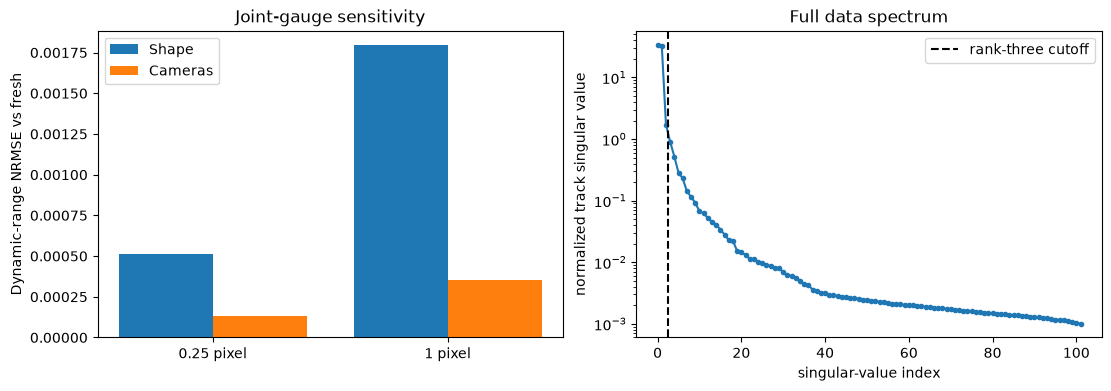

{
  "fresh_runtime_seconds": 0.006487199978437275,
  "shape_metrics": {
    "ncc": 1.0000000000000002,
    "nrmse": 5.754964611021643e-16
  },
  "camera_metrics": {
    "ncc": 1.0,
    "nrmse": 4.732685779381832e-16
  },
  "image_reprojection_rmse_pixel": 2.308463843254198,
  "affine_only_reprojection_rmse_pixel": 2.308463843254198,
  "mean_metric_camera_gram_error": 0.017953834873394317,
  "mean_affine_camera_gram_error": 0.46304615099085966,
  "robustness": [
    {
      "sigma_pixel": 0.25,
      "shape_nrmse_vs_fresh": 0.0005104743875098243,
      "camera_nrmse_vs_fresh": 0.00013416003168454182,
      "reprojection_rmse_pixel": 2.3233651921228327
    },
    {
      "sigma_pixel": 1.0,
      "shape_nrmse_vs_fresh": 0.0017946504618287658,
      "camera_nrmse_vs_fresh": 0.0003536383829521496,
      "reprojection_rmse_pixel": 2.5083369506002624
    }
  ],
  "judge": {
    "reconstruction_ncc": 0.9999999999999997,
    "reconstruction_nrmse": 5.619064049854233e-16,
    "cameras_ncc": 1.0

In [7]:
rng=np.random.default_rng(20261026);robustness=[]
for sigma in [.25,1.]:
    noisy=tracks+sigma*rng.normal(size=tracks.shape)
    ns,nc,nt,nd=reconstruct(noisy);ns,nc,_=joint_alignment(ns,nc,shape)
    robustness.append({'sigma_pixel':sigma,'shape_nrmse_vs_fresh':metrics(ns,shape)['nrmse'],'camera_nrmse_vs_fresh':metrics(nc,cameras)['nrmse'],'reprojection_rmse_pixel':float(np.sqrt(np.mean((forward(ns,nc,nt)-noisy)**2)))})
fig,ax=plt.subplots(1,2,figsize=(11,3.8),constrained_layout=True)
x=np.arange(2)
ax[0].bar(x-.2,[r['shape_nrmse_vs_fresh'] for r in robustness],.4,label='Shape');ax[0].bar(x+.2,[r['camera_nrmse_vs_fresh'] for r in robustness],.4,label='Cameras');ax[0].set(xticks=x,xticklabels=['0.25 pixel','1 pixel'],ylabel='Dynamic-range NRMSE vs fresh',title='Joint-gauge sensitivity');ax[0].legend()
ax[1].plot(info['singular_values'],'o-',markersize=3);ax[1].set_yscale('log');ax[1].axvline(2.5,color='black',linestyle='--',label='rank-three cutoff');ax[1].set(xlabel='singular-value index',ylabel='normalized track singular value',title='Full data spectrum');ax[1].legend()
plt.show()
measurements={'fresh_runtime_seconds':runtime,'shape_metrics':shape_metrics,'camera_metrics':camera_metrics,'image_reprojection_rmse_pixel':rmse,'affine_only_reprojection_rmse_pixel':affine_rmse,'mean_metric_camera_gram_error':float(gram_error.mean()),'mean_affine_camera_gram_error':float(affine_error.mean()),'robustness':robustness,'judge':report['metrics']}
print(json.dumps(measurements,indent=2))


The full original/local geometric pair agrees within floating-point precision after one joint global gauge. Measured-space residuals and nonzero camera Gram errors remain visible. The affine ablation shows that an unchanged projection error does not guarantee a calibrated three-dimensional shape. Without independent 3D truth, these results establish method reproduction and sensitivity, not absolute reconstruction accuracy.